# Figure 3 — complete response characterization

Sound–Image: Picture Naming, Repeat, Stimulus 0–0.6 s. Decision–Repeat: Lexical Delay, sound, Delay 0–1 s.

The denominators are the fixed sound-defined NMF cohort and its original task-specific comparison inputs. These are not all anatomical insula samples. Counts are reconstructed from the existing native baseline masks, including the approved Picture Naming Stimulus repair. No new significance tests, NMF, event selection or waveforms are computed.

Each Venn region reports electrodes and unique participants (P). Participants may contribute to multiple regions and components; their counts must not be added. “Only” means baseline response detected in one condition only, not a significant difference between conditions. “Neither detected” does not prove absence of activity. Brain colors show the fixed NMF component and contours are descriptive spatial density; all four classes are displayed without gray background points.


In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg")
from pathlib import Path
import sys,json
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display,SVG,Markdown
ROOT=Path('/cwork/ns458/insula-paper')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.supplementary.response_characterization import OUT,IMG,SPECS,prepare,draw_venns,draw_brains,assemble
for font in (Path(sys.prefix)/'fonts').glob('arial*.ttf'):font_manager.fontManager.addfont(str(font))
plt.rcParams.update({'svg.fonttype':'none','font.family':'sans-serif','font.sans-serif':['Arial'],'font.size':7})


In [2]:
counts,chain,versions=prepare()
display(Markdown('## Denominator chain'))
display(chain)
display(Markdown('## Response classes by component'))
display(counts.drop(columns=['subject_list']))


sound_image 81 24 {'Neither': 41, 'A only': 22, 'Both': 11, 'B only': 7}


decision_repeat 123 34 {'Neither': 52, 'Both': 48, 'A only': 13, 'B only': 10}


## Denominator chain

,comparison,component,stage,n_sites,n_subjects
0,sound_image,all,All fixed NMF sites,231,62
1,sound_image,all,NMF sites with subject task record,102,26
2,sound_image,all,Original native-good intersection,81,24
3,sound_image,all,Original task response gate,81,24
4,sound_image,all,Retained paired comparison cohort,81,24
5,sound_image,sensory,All fixed NMF sites,35,19
6,sound_image,sensory,NMF sites with subject task record,15,9
7,sound_image,sensory,Original native-good intersection,12,7
8,sound_image,sensory,Original task response gate,12,7
9,sound_image,sensory,Retained paired comparison cohort,12,7


## Response classes by component

,comparison,component,category,n_sites,n_subjects,n_candidate_sites,n_candidate_subjects
0,sound_image,all,Candidates,81,24,81,24
1,sound_image,all,Sound responsive,33,18,81,24
2,sound_image,all,Image responsive,18,13,81,24
3,sound_image,all,A only,22,15,81,24
4,sound_image,all,Both,11,9,81,24
5,sound_image,all,B only,7,6,81,24
6,sound_image,all,Neither,41,21,81,24
7,sound_image,sensory,Candidates,12,7,12,7
8,sound_image,sensory,Sound responsive,10,7,12,7
9,sound_image,sensory,Image responsive,3,3,12,7


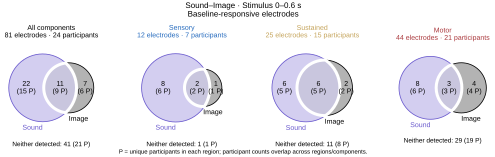

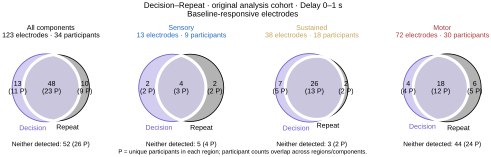

In [2]:
venn_paths={}
for spec in SPECS:
    venn_paths[spec['key']]=draw_venns(spec)
    display(SVG(filename=str(venn_paths[spec['key']])))


Using notebook 3d backend.


Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


Rendered sound_image A only 22 sites


Reading labels from parcellation...


... (7 outputs left out)

Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


Rendered sound_image Neither 41 sites


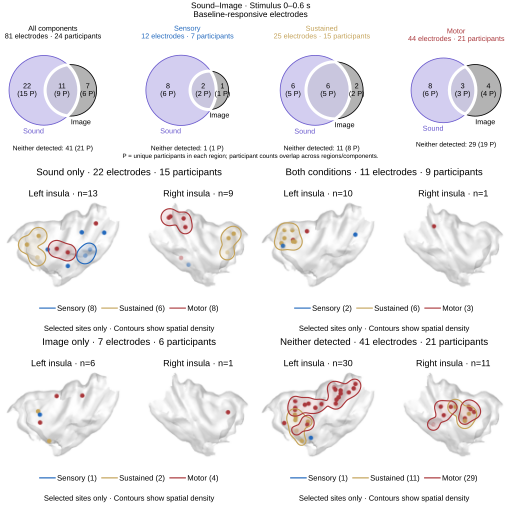

In [4]:
spec=SPECS[0]
sound_brains=draw_brains(spec)
sound_sheet=assemble(spec,venn_paths[spec['key']],sound_brains)
display(SVG(filename=str(sound_sheet)))


Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


Rendered decision_repeat A only 13 sites


Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


... (6 outputs left out)

Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


Rendered decision_repeat Neither 52 sites


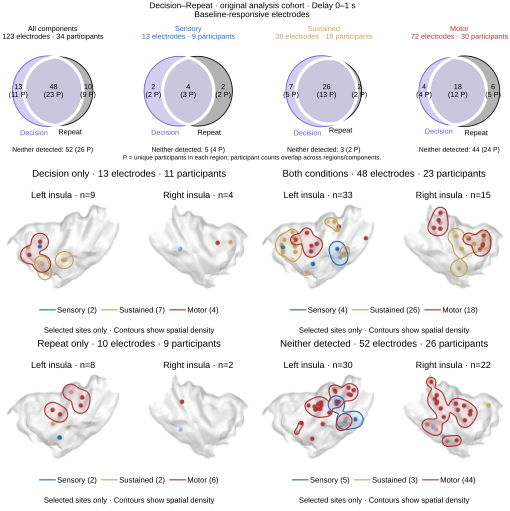

In [5]:
spec=SPECS[1]
decision_brains=draw_brains(spec)
decision_sheet=assemble(spec,venn_paths[spec['key']],decision_brains)
display(SVG(filename=str(decision_sheet)))


## Existing subset panels and assembly audit

The earlier supplied assembled screenshot mixed the 18 Picture-responsive heatmap rows (3/8/7) with the 11 common-site map (2/6/3). The current local Sound–Image heatmap and selected-site brain map must both use the 11 common sites; the Decision–Repeat subset panels must both use the same 29 Decision > Repeat sites (3/14/12). Their data rows, numeric matrices, vector labels and notebook outputs are checked above, and the current panels are copied into `review_bundle/` for assembling a consistent version.

Only the previously supplied assembled screenshot and accessible local panels can be checked. A newer editable manuscript assembly was not supplied.


In [6]:
display(versions)
print('Detailed tables:',OUT/'Figure3_denominators_and_participants.xlsx')
print('Current subset panels:',OUT/'review_bundle')


{'local_panels': [{'comparison': 'sound_image',
   'selected_sites': 11,
   'component_counts': {'sensory': 2, 'sustain': 6, 'motor': 3},
   'current_heatmap_rows_and_matrices_agree': True,
   'current_svg_and_notebook_labels_agree': True,
   'heatmap': '/cwork/ns458/insula-paper/img/supplementary/sound_image_test/fig3_sound_image_test.svg',
   'brain': '/cwork/ns458/insula-paper/img/supplementary/sound_image_test/fig3_sound_image_common_stimulus_brain.svg',
   'heatmap_sha256': 'adb4e63c303f2d941fd134b0de080d08d05dc2ca5dbe1b6e804e2b9fb9d22e42',
   'brain_sha256': '52d3ea410a2768025dfeb1df57ba82a1d92a440fa78ad19bc37b877e6a56d9df'},
  {'comparison': 'decision_repeat',
   'selected_sites': 29,
   'component_counts': {'sensory': 3, 'sustain': 14, 'motor': 12},
   'current_heatmap_rows_and_matrices_agree': True,
   'current_svg_and_notebook_labels_agree': True,
   'heatmap': '/cwork/ns458/insula-paper/img/supplementary/decision_repeat_test/fig3_decision_repeat_test.svg',
   'brain': '/cwor

Detailed tables: /cwork/ns458/insula-paper/results/supplementary/fig3_response_characterization_2026-10-23/Figure3_denominators_and_participants.xlsx
Current subset panels: /cwork/ns458/insula-paper/results/supplementary/fig3_response_characterization_2026-10-23/review_bundle


## Complete paired native-good cohort before the old response gate

A denominator audit found 135 native-good paired Lexical Delay NMF sites (35 participants), of which 12 were excluded by the historical any-phase sound-response gate before constructing the existing 123-site comparison. Directly reading both original Delay masks confirms that all 12 are in the “Neither detected” class during Delay 0–1 s. The complete descriptive denominator is therefore 135, with 13 Decision-only, 48 Both, 10 Repeat-only and 64 Neither-detected sites.

The following extra characterization displays all 135 without altering the original 123-site mean curves, condition tests or 29-site difference subset. The original 123-site sheet above is retained explicitly for comparison; the all-native-good sheet is a separate descriptive audit. Sound–Image has no corresponding response gate and remains 81 sites / 24 participants.


,comparison,component,category,n_sites,n_subjects,n_candidate_sites,n_candidate_subjects
0,decision_repeat_pre_gate,all,Candidates,135,35,135,35
1,decision_repeat_pre_gate,all,Decision responsive,61,26,135,35
2,decision_repeat_pre_gate,all,Repeat responsive,58,25,135,35
3,decision_repeat_pre_gate,all,A only,13,11,135,35
4,decision_repeat_pre_gate,all,Both,48,23,135,35
5,decision_repeat_pre_gate,all,B only,10,9,135,35
6,decision_repeat_pre_gate,all,Neither,64,28,135,35
7,decision_repeat_pre_gate,sensory,Candidates,15,9,15,9
8,decision_repeat_pre_gate,sensory,Decision responsive,6,5,15,9
9,decision_repeat_pre_gate,sensory,Repeat responsive,6,4,15,9


Using notebook 3d backend.


Reading labels from parcellation...


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot


   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


Rendered decision_repeat_pre_gate Neither 64 sites


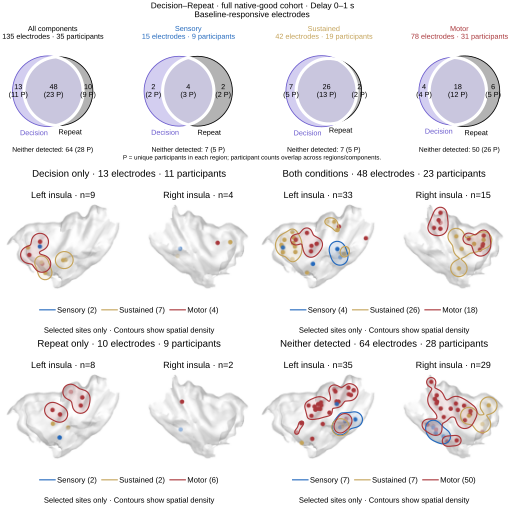

In [3]:
from src.supplementary.response_characterization import draw_brain_class
import pandas as pd
pre_gate_spec=dict(SPECS[1],key='decision_repeat_pre_gate',title='Decision–Repeat · full native-good cohort')
pre_gate_counts=pd.read_csv(OUT/'decision_repeat_pre_gate_component_response_counts.csv')
display(pre_gate_counts.drop(columns=['subject_list']))
# Three response-positive classes have exactly the original membership.
old=pd.read_csv(OUT/'decision_repeat_electrode_membership.csv')
full=pd.read_csv(OUT/'decision_repeat_pre_gate_electrode_membership.csv')
for region in ['A only','Both','B only']:
    assert set(old.loc[old.response_class.eq(region),'electrode'])==set(full.loc[full.response_class.eq(region),'electrode'])
venn135=draw_venns(pre_gate_spec)
brain135=[IMG/f"fig3_decision_repeat_{r}_brain.svg" for r in ['a_only','both','b_only']]
brain135.append(draw_brain_class(pre_gate_spec,'Neither'))
pre_gate_sheet=assemble(pre_gate_spec,venn135,brain135)
display(SVG(filename=str(pre_gate_sheet)))
# Export a single front-page count table for the full native-good comparison pools.
full_counts=pd.concat([pd.read_csv(OUT/'component_response_counts.csv').query("comparison == 'sound_image'"),pre_gate_counts],ignore_index=True)
full_counts.to_csv(OUT/'full_native_component_response_counts.csv',index=False)
with pd.ExcelWriter(OUT/'Figure3_denominators_and_participants.xlsx',mode='a',engine='openpyxl',if_sheet_exists='replace') as writer:
    full_counts.to_excel(writer,sheet_name='Full native response counts',index=False)
    writer.book.move_sheet(writer.book['Full native response counts'],offset=-writer.book.index(writer.book['Full native response counts']))
